In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


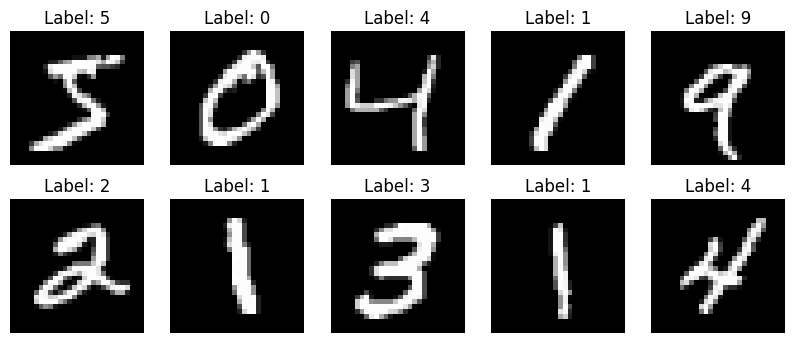

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(X_train[i], cmap='gray')
  plt.title(f'Label: {y_train[i]}')
  plt.axis('off')
plt.show()

In [4]:
X_train = X_train.reshape(-1, 28 * 28).astype('float32') / 255.0
X_test = X_test.reshape(-1, 28 * 28).astype('float32') / 255.0

print(X_train.shape, X_test.shape)

(60000, 784) (10000, 784)


In [5]:
ann = tf.keras.models.Sequential()
ann.add(tf.keras.layers.Input(shape=(784,)))
ann.add(tf.keras.layers.Dense(units=128, activation='relu'))
ann.add(tf.keras.layers.Dense(units=64, activation='relu'))
ann.add(tf.keras.layers.Dense(units=10, activation='softmax'))

ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
ann.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

In [7]:
history = ann.fit(X_train, y_train,
                  batch_size=32,
                  epochs=10,
                  validation_split=0.1)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9245 - loss: 0.2615 - val_accuracy: 0.9658 - val_loss: 0.1106
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9668 - loss: 0.1110 - val_accuracy: 0.9728 - val_loss: 0.0980
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9764 - loss: 0.0772 - val_accuracy: 0.9760 - val_loss: 0.0820
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9820 - loss: 0.0578 - val_accuracy: 0.9790 - val_loss: 0.0829
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9850 - loss: 0.0455 - val_accuracy: 0.9758 - val_loss: 0.0866
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9881 - loss: 0.0371 - val_accuracy: 0.9802 - val_loss: 0.0796
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9899 - loss: 0.0310 - val_accuracy: 0.9757 - val_loss: 0.0894
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9916 - loss: 0.0

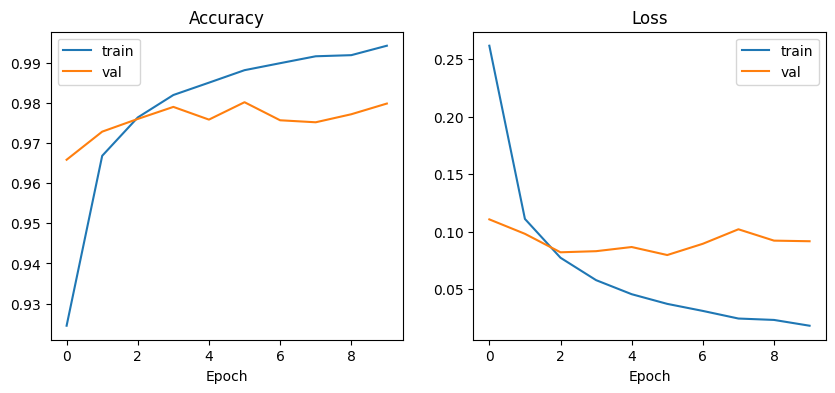

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.show()

In [9]:
test_loss, test_acc = ann.evaluate(X_test, y_test)
print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9779 - loss: 0.0881
Test accuracy: 0.9779000282287598


In [10]:
y_pred = np.argmax(ann.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
print(cm)
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
[[ 966    0    1    2    1    2    5    0    1    2]
 [   0 1117    7    2    0    1    2    1    5    0]
 [   2    0 1012    7    1    0    0    5    4    1]
 [   2    0    1  982    0   10    0    3    6    6]
 [   0    0    3    1  957    1    4    3    1   12]
 [   1    0    0    1    1  873    5    0    5    6]
 [   4    1    1    1    6    2  942    0    1    0]
 [   1    2    8    4    3    0    0  995    2   13]
 [   2    1    2    8    2    1    1    3  951    3]
 [   1    2    0    4    7    3    0    2    6  984]]
Accuracy: 0.9779
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.98      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.97      0.97      0.97      1010
           4       0.98      0.97      0.98       982
           5       0.98      0.98      0.98       892
           6       0.98      0.9

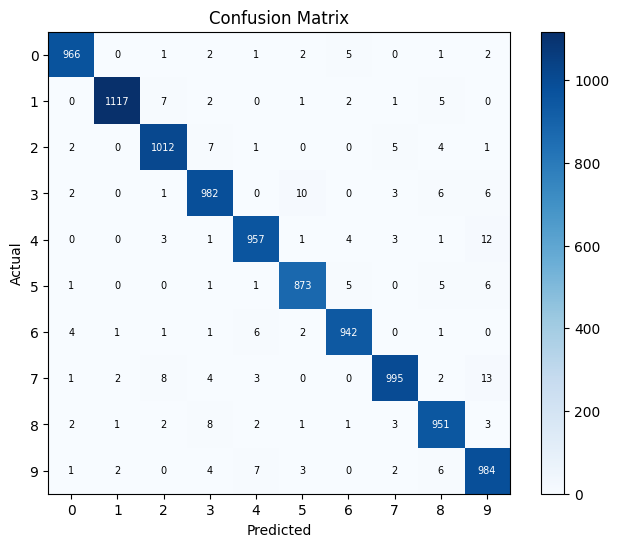

In [11]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(range(10))
plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=7)
plt.show()

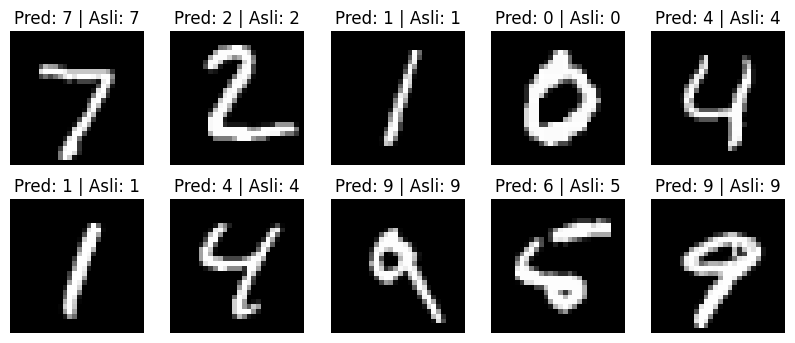

In [12]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f'Pred: {y_pred[i]} | Asli: {y_test[i]}')
    plt.axis('off')
plt.show()

In [13]:
def build_model(units, activation):
  model = tf.keras.models.Sequential()
  model.add(tf.keras.layers.Input(shape=(784,)))
  for u in units:
    model.add(tf.keras.layers.Dense(units=u, activation=activation))
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))
  model.compile(optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
  return model

configs = {
  'ReLU 128-64':   ([128, 64], 'relu'),
  'ReLU 256-128':  ([256, 128], 'relu'),
  'Tanh 128-64':   ([128, 64], 'tanh'),
  'Sigmoid 128-64': ([128, 64], 'sigmoid'),
}

results = {}
for name, (units, act) in configs.items():
  print('Training:', name)
  m = build_model(units, act)
  m.fit(X_train, y_train, batch_size=32, epochs=10, validation_split=0.1, verbose=0)
  _, acc = m.evaluate(X_test, y_test, verbose=0)
  results[name] = acc
  print(f'  Test accuracy: {acc:.4f}')

print()
for name, acc in results.items():
  print(f'{name}: {acc:.4f}')

Training: ReLU 128-64
  Test accuracy: 0.9742
Training: ReLU 256-128
  Test accuracy: 0.9809
Training: Tanh 128-64
  Test accuracy: 0.9779
Training: Sigmoid 128-64
  Test accuracy: 0.9776

ReLU 128-64: 0.9742
ReLU 256-128: 0.9809
Tanh 128-64: 0.9779
Sigmoid 128-64: 0.9776


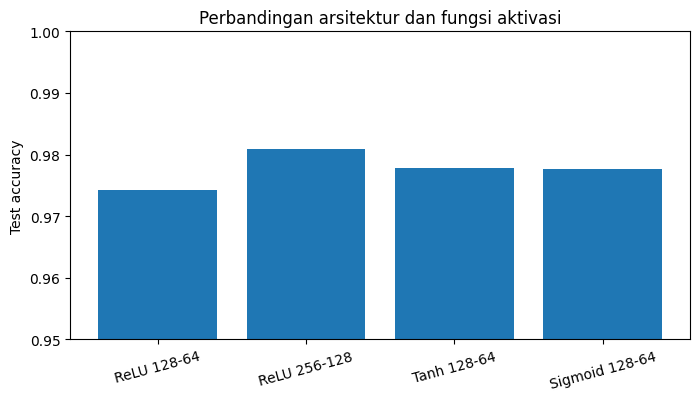

In [14]:
plt.figure(figsize=(8, 4))
plt.bar(results.keys(), results.values())
plt.ylim(0.95, 1.0)
plt.ylabel('Test accuracy')
plt.title('Perbandingan arsitektur dan fungsi aktivasi')
plt.xticks(rotation=15)
plt.show()